# Loan Default Risk Scoring Project

### 1. Problem Statement
When a bank or lending institution issues a loan, there is always a risk that the borrower might not be able to pay it back. This is called **defaulting** on a loan. If too many people default, the bank loses a lot of money.

Our goal is to build a smart system (a machine learning model) that looks at a borrower's profile (like their income, employment history, credit history, etc.) and predicts how likely they are to default. This helps the bank make safer lending decisions.

### 2. How We Are Going to Solve It
We will tackle this step-by-step:
1. **Explore and Clean the Data:** Look at our dataset (`loan-data.csv`), handle missing values, and understand the features.
2. **Analyze & Visualize:** Create charts to see how different factors relate to loan defaults.
3. **Prepare the Data:** Convert text columns into numbers and scale our data so our machine learning model can understand it.
4. **Train a Model:** Teach a model to recognize the patterns of a "safe" borrower versus a "risky" borrower.
5. **Evaluate:** Test how well our model predicts defaults on new, unseen data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Set plotting style
sns.set_theme(style='whitegrid')

# Load the dataset
df = pd.read_csv('/content/loan-data.csv')

# Display the first few rows of the data
print("Dataset successfully loaded!")
display(df.head())

Dataset successfully loaded!


,id,loan_amnt,term,int_rate,installment,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,total_pymnt
0,1077501,5000,36 months,10.65%,162.87,RENT,24000.0,Verified,Dec-11,Fully Paid,credit_card,5863.155187
1,1077430,2500,60 months,15.27%,59.83,RENT,30000.0,Source Verified,Dec-11,Charged Off,car,1008.710000
2,1077175,2400,36 months,15.96%,84.33,RENT,12252.0,Not Verified,Dec-11,Fully Paid,small_business,3005.666844
3,1076863,10000,36 months,13.49%,339.31,RENT,49200.0,Source Verified,Dec-11,Fully Paid,other,12231.890000
4,1075358,3000,60 months,12.69%,67.79,RENT,80000.0,Source Verified,Dec-11,Current,other,3513.330000


## Exploratory Data Analysis (EDA)

In this section, we will inspect the quality of our data, clean key columns (like `int_rate` and `term`), and visualize relationships using univariate, bivariate, and multivariate analysis.

In [2]:
# 1. Data Quality & Inspection
print("--- Data Information ---")
print(df.info())

print("\n--- Missing Values count ---")
print(df.isnull().sum())

print("\n--- Unique value counts for categorical features ---")
for col in ['term', 'home_ownership', 'verification_status', 'loan_status', 'purpose']:
    if col in df.columns:
        print(f"{col}: {df[col].nunique()} unique values")

--- Data Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39717 entries, 0 to 39716
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   39717 non-null  int64  
 1   loan_amnt            39717 non-null  int64  
 2   term                 39717 non-null  object 
 3   int_rate             39717 non-null  object 
 4   installment          39717 non-null  float64
 5   home_ownership       39717 non-null  object 
 6   annual_inc           39717 non-null  float64
 7   verification_status  39717 non-null  object 
 8   issue_d              39717 non-null  object 
 9   loan_status          39717 non-null  object 
 10  purpose              39717 non-null  object 
 11  total_pymnt          39717 non-null  float64
dtypes: float64(3), int64(2), object(7)
memory usage: 3.6+ MB
None

--- Missing Values count ---
id                     0
loan_amnt              0
term               

### Data Cleaning
We observed that:
1. `int_rate` has a `%` sign and is a string. We must strip `%` and convert it to float.
2. `term` has text like `' 36 months'` or `' 60 months'`. We can clean it to store just the numeric value.
3. We also need to inspect `loan_status` to define our target variable.

In [3]:
# 2. Clean 'int_rate'
if df['int_rate'].dtype == 'object':
    df['int_rate'] = df['int_rate'].str.rstrip('%').astype('float')

# Clean 'term'
if df['term'].dtype == 'object':
    df['term'] = df['term'].str.replace(' months', '').str.strip().astype('int')

print("Data cleaning completed. Let's verify the updated data types:")
display(df[['int_rate', 'term']].head())

Data cleaning completed. Let's verify the updated data types:


,int_rate,term
0,10.65,36
1,15.27,60
2,15.96,36
3,13.49,36
4,12.69,60


### Univariate Analysis
Let's analyze individual columns to see how they are distributed. We will look at:
* The distribution of the target variable (`loan_status`).
* The distribution of the numerical features (`loan_amnt`, `int_rate`).

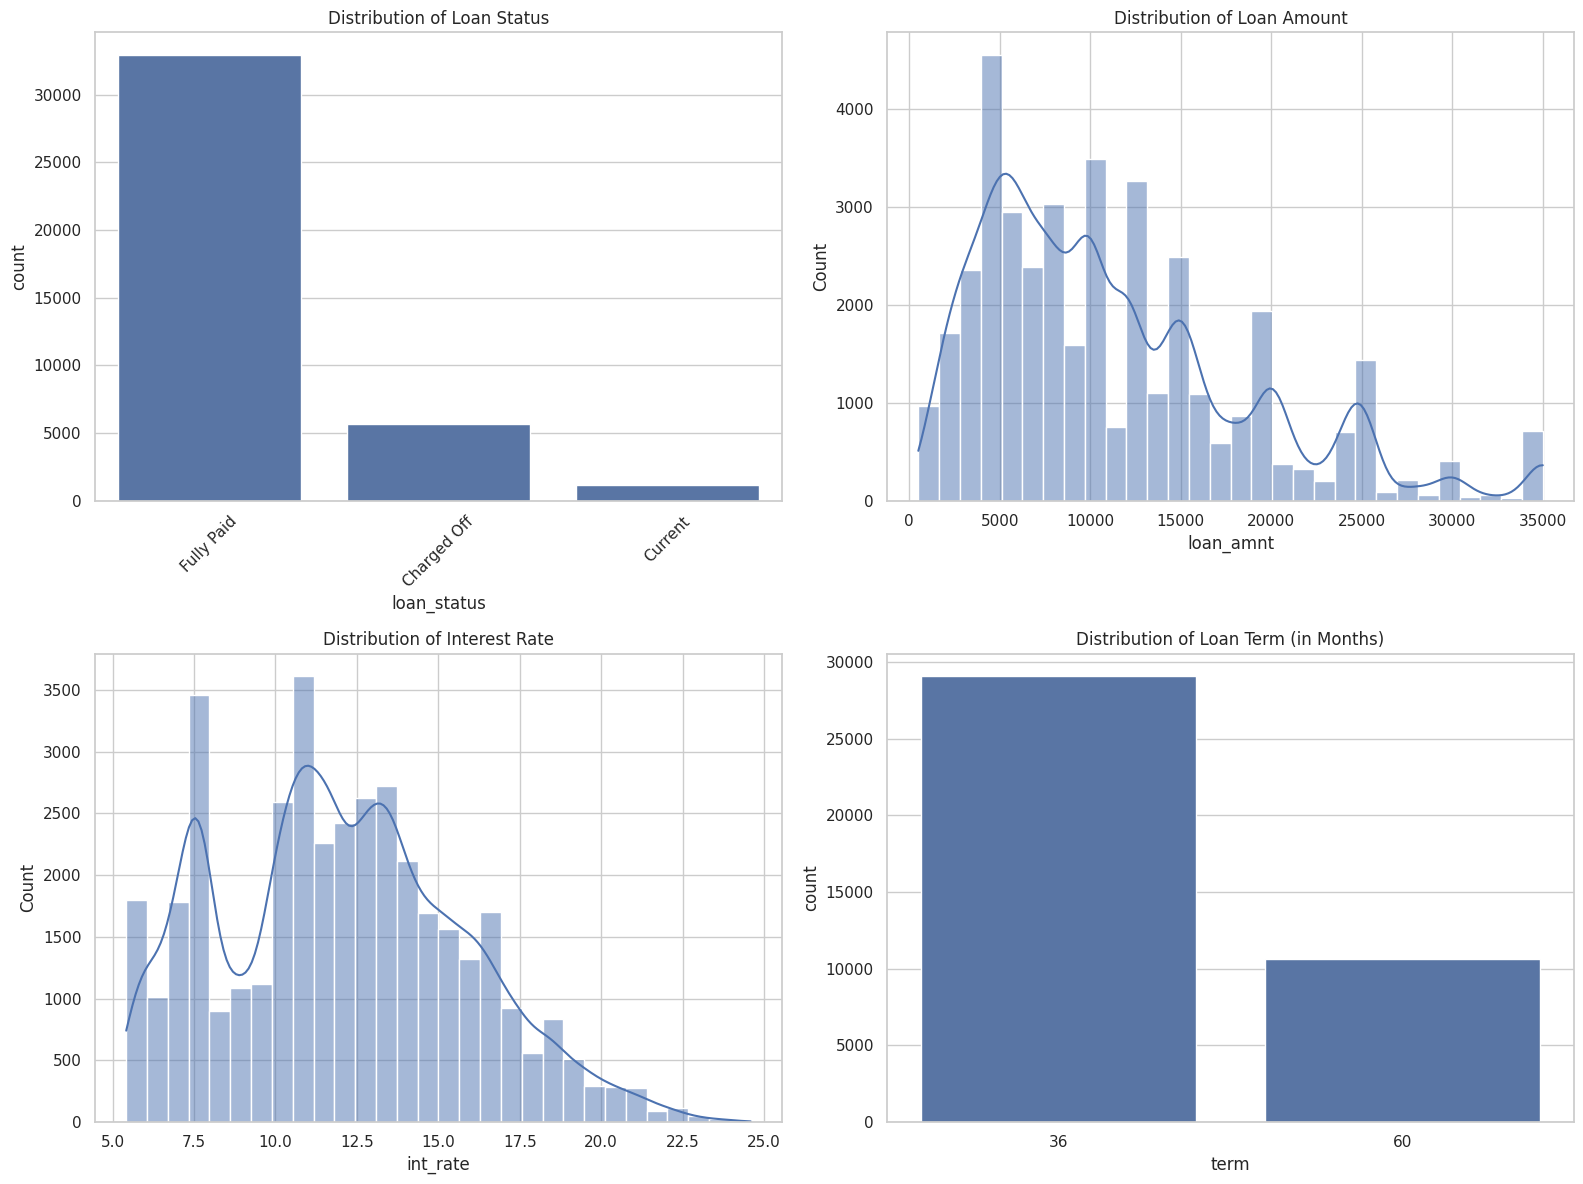

In [4]:
# 3. Univariate Analysis
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Target Variable: loan_status
sns.countplot(data=df, x='loan_status', ax=axes[0, 0], order=df['loan_status'].value_counts().index)
axes[0, 0].set_title('Distribution of Loan Status')
axes[0, 0].tick_params(axis='x', rotation=45)

# Feature: loan_amnt
sns.histplot(data=df, x='loan_amnt', bins=30, kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Distribution of Loan Amount')

# Feature: int_rate
sns.histplot(data=df, x='int_rate', bins=30, kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Distribution of Interest Rate')

# Feature: term
sns.countplot(data=df, x='term', ax=axes[1, 1])
axes[1, 1].set_title('Distribution of Loan Term (in Months)')

plt.tight_layout()
plt.show()

### Bivariate Analysis
Now we will see how our predictors relate to the target variable (`loan_status`). For clean comparisons, we will focus primarily on **Fully Paid** vs **Charged Off** (defaults).

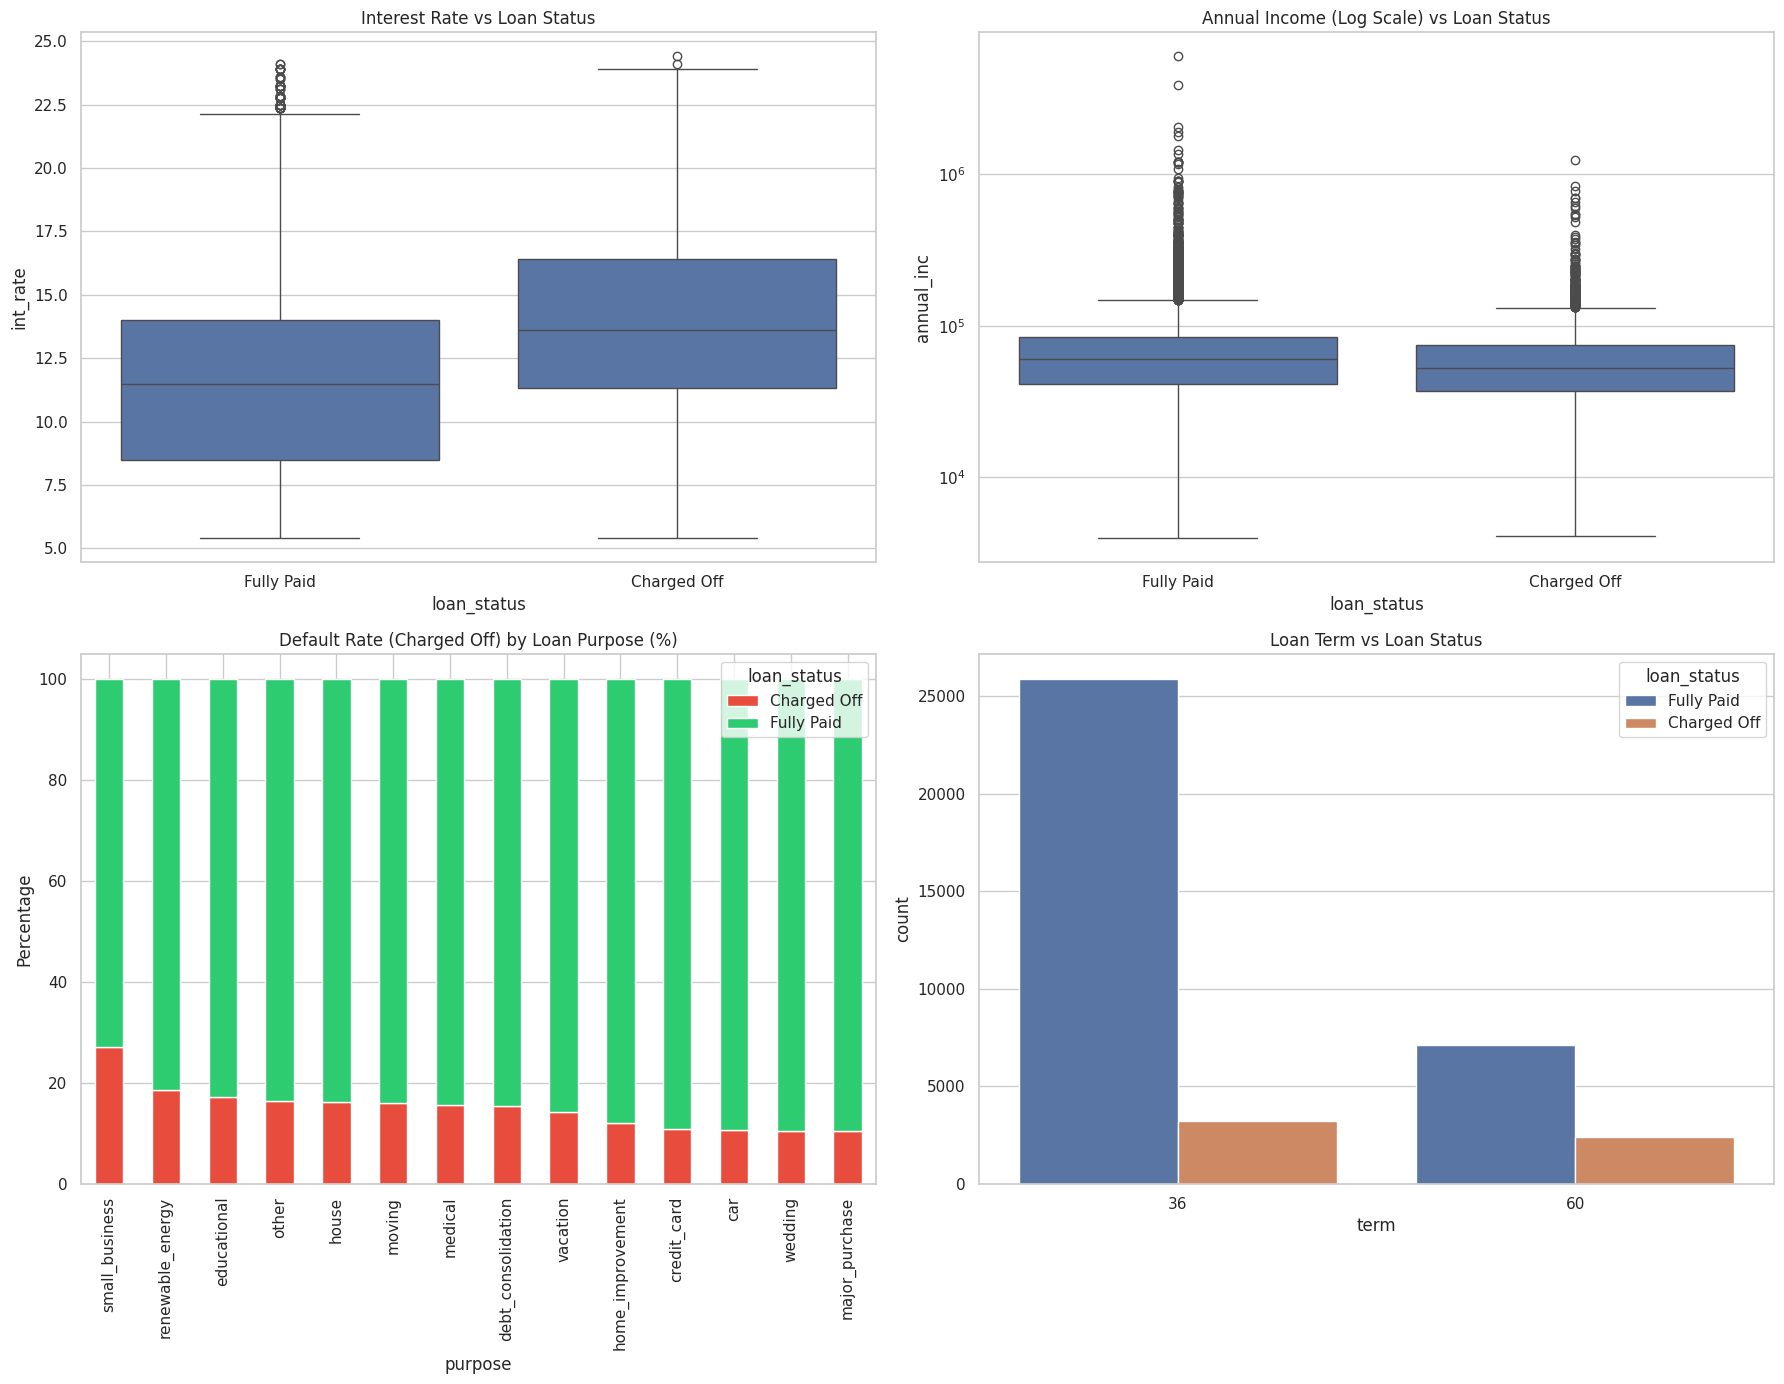

In [5]:
# 4. Bivariate Analysis
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# Filter out 'Current' loans to focus on defaulted (Charged Off) vs non-defaulted (Fully Paid)
completed_loans = df[df['loan_status'].isin(['Fully Paid', 'Charged Off'])]

# Relationship 1: Interest Rate vs Loan Status
sns.boxplot(data=completed_loans, x='loan_status', y='int_rate', ax=axes[0, 0])
axes[0, 0].set_title('Interest Rate vs Loan Status')

# Relationship 2: Annual Income vs Loan Status (using log-scale due to outliers)
sns.boxplot(data=completed_loans, x='loan_status', y='annual_inc', ax=axes[0, 1])
axes[0, 1].set_yscale('log')
axes[0, 1].set_title('Annual Income (Log Scale) vs Loan Status')

# Relationship 3: Purpose vs Loan Status
purpose_counts = completed_loans.groupby(['purpose', 'loan_status']).size().unstack(fill_value=0)
purpose_pct = purpose_counts.div(purpose_counts.sum(axis=1), axis=0) * 100
purpose_pct.sort_values(by='Charged Off', ascending=False).plot(kind='bar', stacked=True, ax=axes[1, 0], color=['#e74c3c', '#2ecc71'])
axes[1, 0].set_title('Default Rate (Charged Off) by Loan Purpose (%)')
axes[1, 0].set_ylabel('Percentage')

# Relationship 4: Term vs Loan Status
sns.countplot(data=completed_loans, x='term', hue='loan_status', ax=axes[1, 1])
axes[1, 1].set_title('Loan Term vs Loan Status')

plt.tight_layout()
plt.show()

### Multivariate Analysis
Let's calculate and plot a correlation matrix across the key numerical features to check for potential multicollinearity before building predictive models.

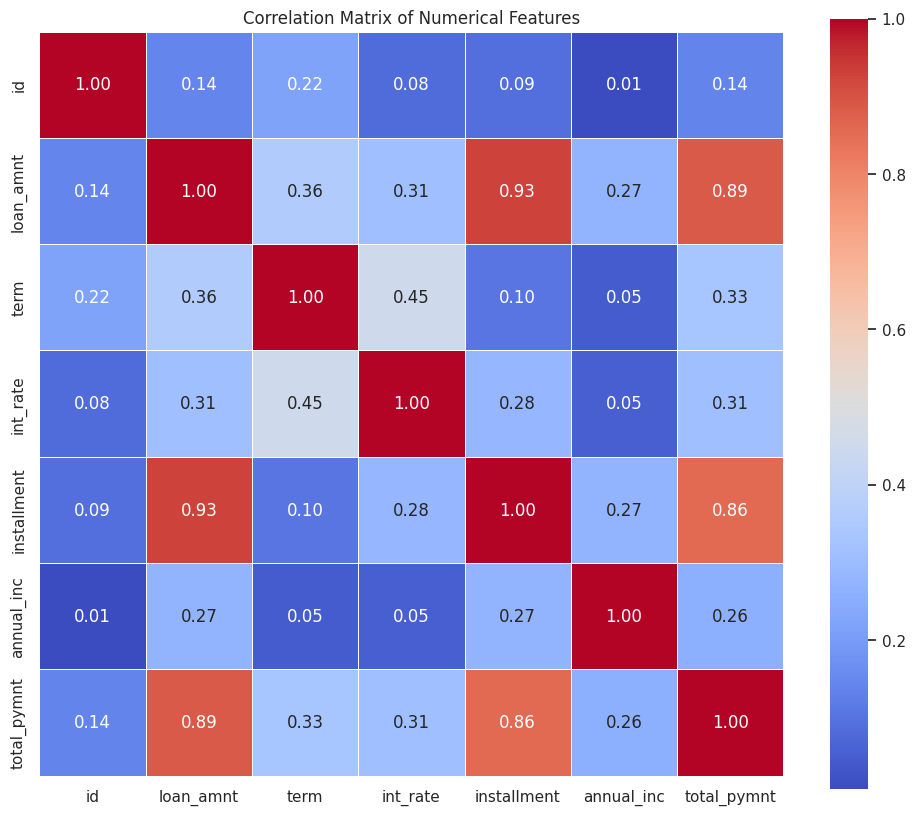

In [6]:
# 5. Multivariate Analysis (Correlation Matrix)
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

## Data Preprocessing and Feature Engineering

Now we will prepare the dataset for Machine Learning. We will perform the following steps:
1. **Define the Target Variable:** Create a binary target `default` (1 = Charged Off, 0 = Fully Paid) and remove current active loans.
2. **Feature Selection:** Drop redundant/high-correlation columns (like `installment` and `id`).
3. **Categorical Encoding:** Convert text columns into numeric representation using One-Hot Encoding.
4. **Train-Test Split:** Split the data into 80% training and 20% validation sets.
5. **Feature Scaling:** Normalize our numerical data so that models perform optimally.

In [7]:
# 1. Prepare target and filter data
# We only keep historical completed loans ('Fully Paid' and 'Charged Off')
ml_df = df[df['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
ml_df['default'] = ml_df['loan_status'].apply(lambda x: 1 if x == 'Charged Off' else 0)

# 2. Select features and drop highly correlated/unnecessary identifiers
features_to_drop = ['id', 'loan_status', 'issue_d', 'installment', 'total_pymnt']
ml_df = ml_df.drop(columns=features_to_drop)

# 3. Handle Categorical Encoding
categorical_cols = ['home_ownership', 'verification_status', 'purpose']
ml_df = pd.get_dummies(ml_df, columns=categorical_cols, drop_first=True)

# Separate predictors and target
X = ml_df.drop(columns=['default'])
y = ml_df['default']

# 4. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 5. Feature Scaling
scaler = StandardScaler()
numerical_cols = ['loan_amnt', 'term', 'int_rate', 'annual_inc']

X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

print(f"Preprocessed training set shape: {X_train.shape}")
print(f"Preprocessed testing set shape: {X_test.shape}")
print("\nClass distribution in Training Set:")
print(y_train.value_counts(normalize=True))

Preprocessed training set shape: (30861, 23)
Preprocessed testing set shape: (7716, 23)

Class distribution in Training Set:
default
0    0.85412
1    0.14588
Name: proportion, dtype: float64


## Model Training and Evaluation

In this phase, we will train and compare two machine learning models to predict loan defaults:
1. **Logistic Regression:** A reliable baseline model that is highly interpretable.
2. **Random Forest Classifier:** An ensemble tree-based method capable of discovering complex relationships in the data.

### Evaluation Metrics
Since our classes are imbalanced (only ~14.6% of loans default), raw accuracy is not a reliable metric. Instead, we will evaluate using:
- **Precision & Recall:** Especially recall for class `1` (defaults), showing what percentage of actual defaults we correctly caught.
- **ROC-AUC Score:** Measures how well the model distinguishes between safe loans and high-risk defaults.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# --- 1. Logistic Regression Model ---
print("=== Training Logistic Regression ===")
lr_model = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)
lr_probs = lr_model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, lr_preds))
print(f"ROC-AUC Score: {roc_auc_score(y_test, lr_probs):.4f}")

# --- 2. Random Forest Model ---
print("\n=== Training Random Forest ===")
rf_model = RandomForestClassifier(random_state=42, class_weight='balanced', n_estimators=100, max_depth=10, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)
rf_probs = rf_model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, rf_preds))
print(f"ROC-AUC Score: {roc_auc_score(y_test, rf_probs):.4f}")

=== Training Logistic Regression ===
Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.67      0.77      6591
           1       0.24      0.62      0.35      1125

    accuracy                           0.66      7716
   macro avg       0.58      0.64      0.56      7716
weighted avg       0.81      0.66      0.71      7716

ROC-AUC Score: 0.6965

=== Training Random Forest ===
Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.72      0.80      6591
           1       0.26      0.56      0.35      1125

    accuracy                           0.70      7716
   macro avg       0.58      0.64      0.58      7716
weighted avg       0.81      0.70      0.74      7716

ROC-AUC Score: 0.6945


## Visual Model Evaluation

To fully evaluate our risk scoring models, we will plot the **Confusion Matrices** (to see actual vs. predicted default counts) and the **ROC Curves** (to visualize the true positive rate versus false positive rate trade-offs).

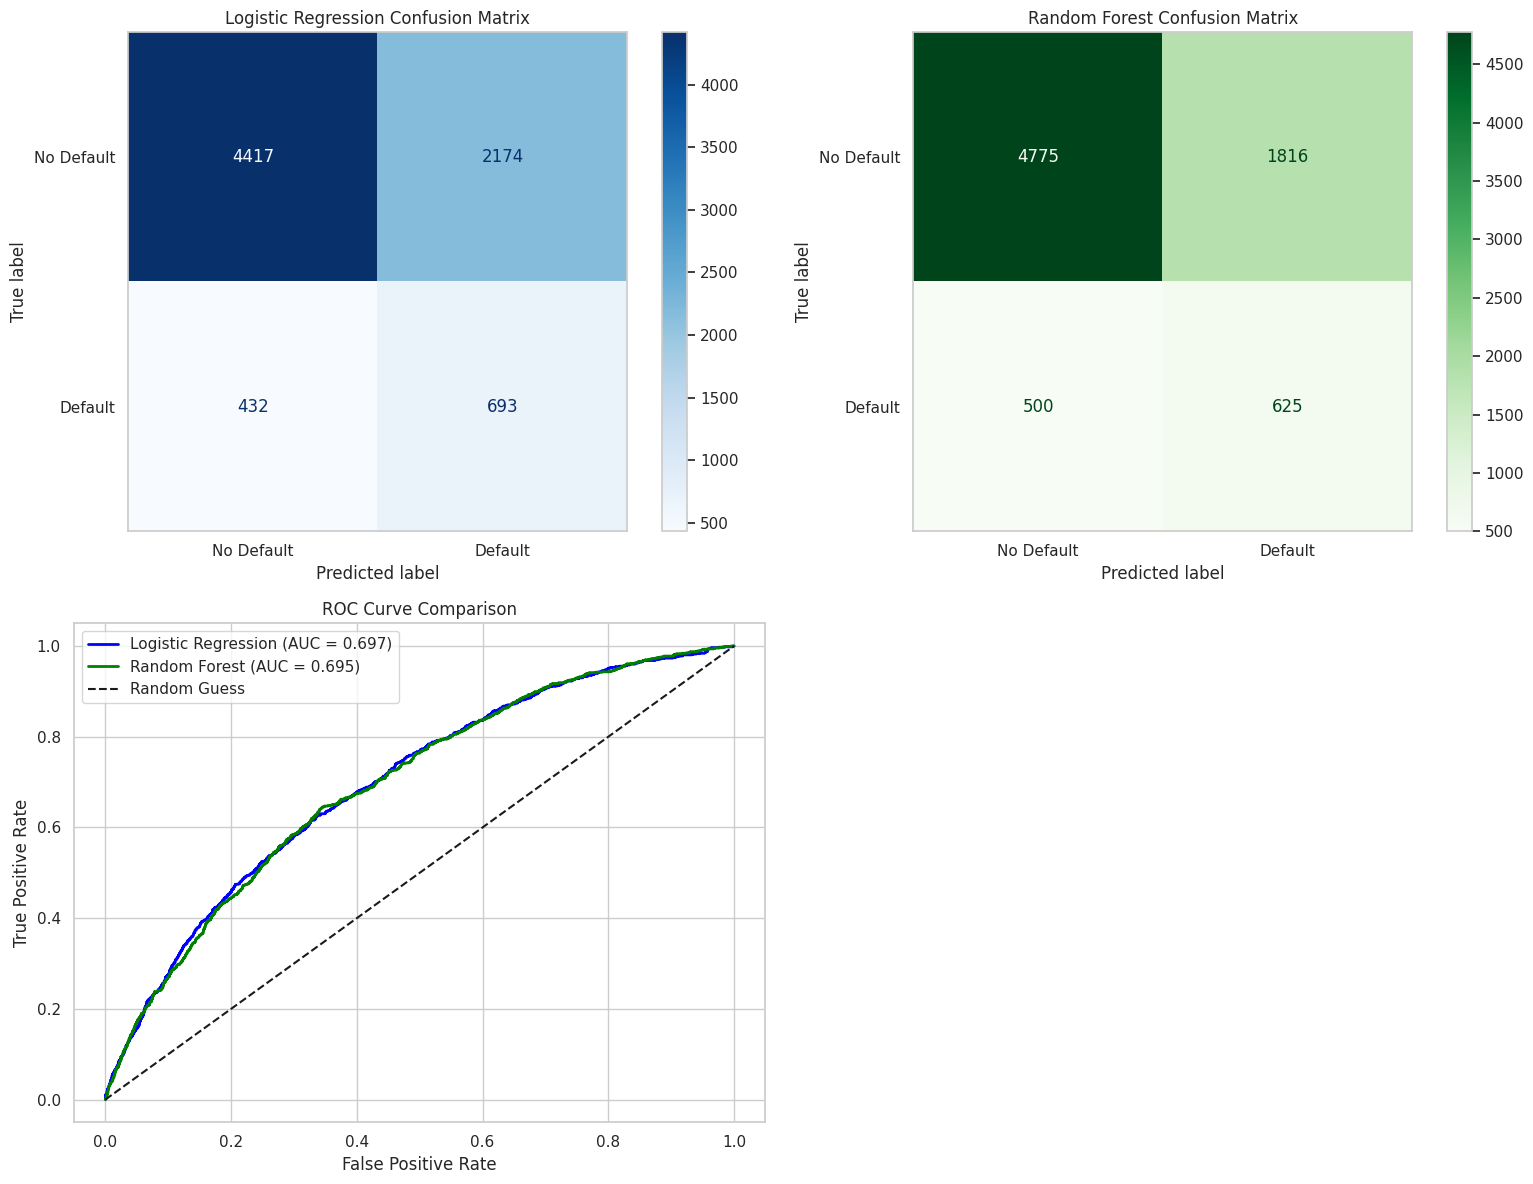

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve

# Set up plot figure
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Confusion Matrix for Logistic Regression
cm_lr = confusion_matrix(y_test, lr_preds)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['No Default', 'Default'])
disp_lr.plot(ax=axes[0, 0], cmap='Blues', values_format='d')
axes[0, 0].set_title('Logistic Regression Confusion Matrix')
axes[0, 0].grid(False)

# 2. Confusion Matrix for Random Forest
cm_rf = confusion_matrix(y_test, rf_preds)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['No Default', 'Default'])
disp_rf.plot(ax=axes[0, 1], cmap='Greens', values_format='d')
axes[0, 1].set_title('Random Forest Confusion Matrix')
axes[0, 1].grid(False)

# 3. ROC Curve Comparison
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_probs)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)

axes[1, 0].plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, lr_probs):.3f})', color='blue', lw=2)
axes[1, 0].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, rf_probs):.3f})', color='green', lw=2)
axes[1, 0].plot([0, 1], [0, 1], 'k--', label='Random Guess')
axes[1, 0].set_xlabel('False Positive Rate')
axes[1, 0].set_ylabel('True Positive Rate')
axes[1, 0].set_title('ROC Curve Comparison')
axes[1, 0].legend()

# Remove empty subplot
fig.delaxes(axes[1, 1])

plt.tight_layout()
plt.show()

## Feature Importance Analysis

To understand which characteristics of the borrowers and loans have the highest impact on our prediction models, we will plot the **Feature Importances** from our trained **Random Forest** model.

/tmp/ipykernel_2028/4160433321.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')


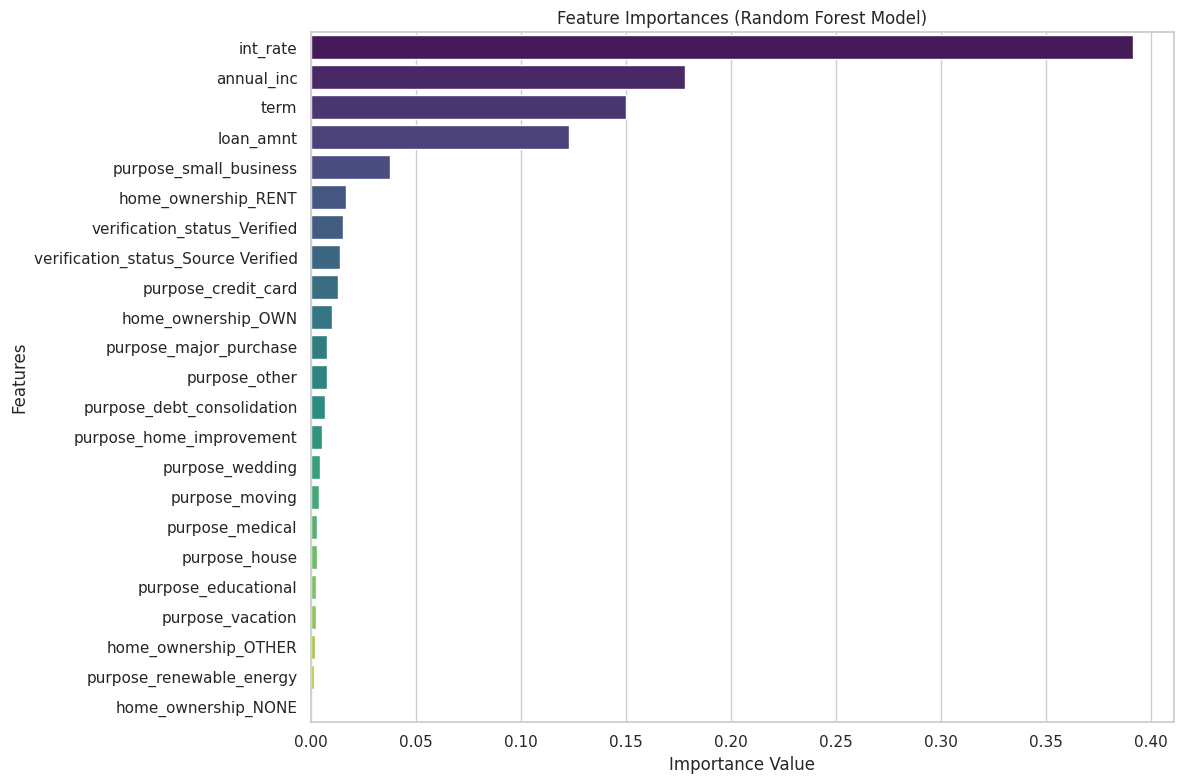

In [10]:
# Get feature importances from the Random Forest model
importances = rf_model.feature_importances_
feature_names = X_train.columns

# Create a DataFrame for visualization
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot the feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')
plt.title('Feature Importances (Random Forest Model)')
plt.xlabel('Importance Value')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

## Comprehensive Project Dashboard

Below, we compile the entire project's insights—spanning Exploratory Data Analysis, Model Comparison (ROC Curves), and Feature Drivers—into one clean, production-ready horizontal visual dashboard. The figure is automatically saved as a high-resolution PNG for easy reporting.

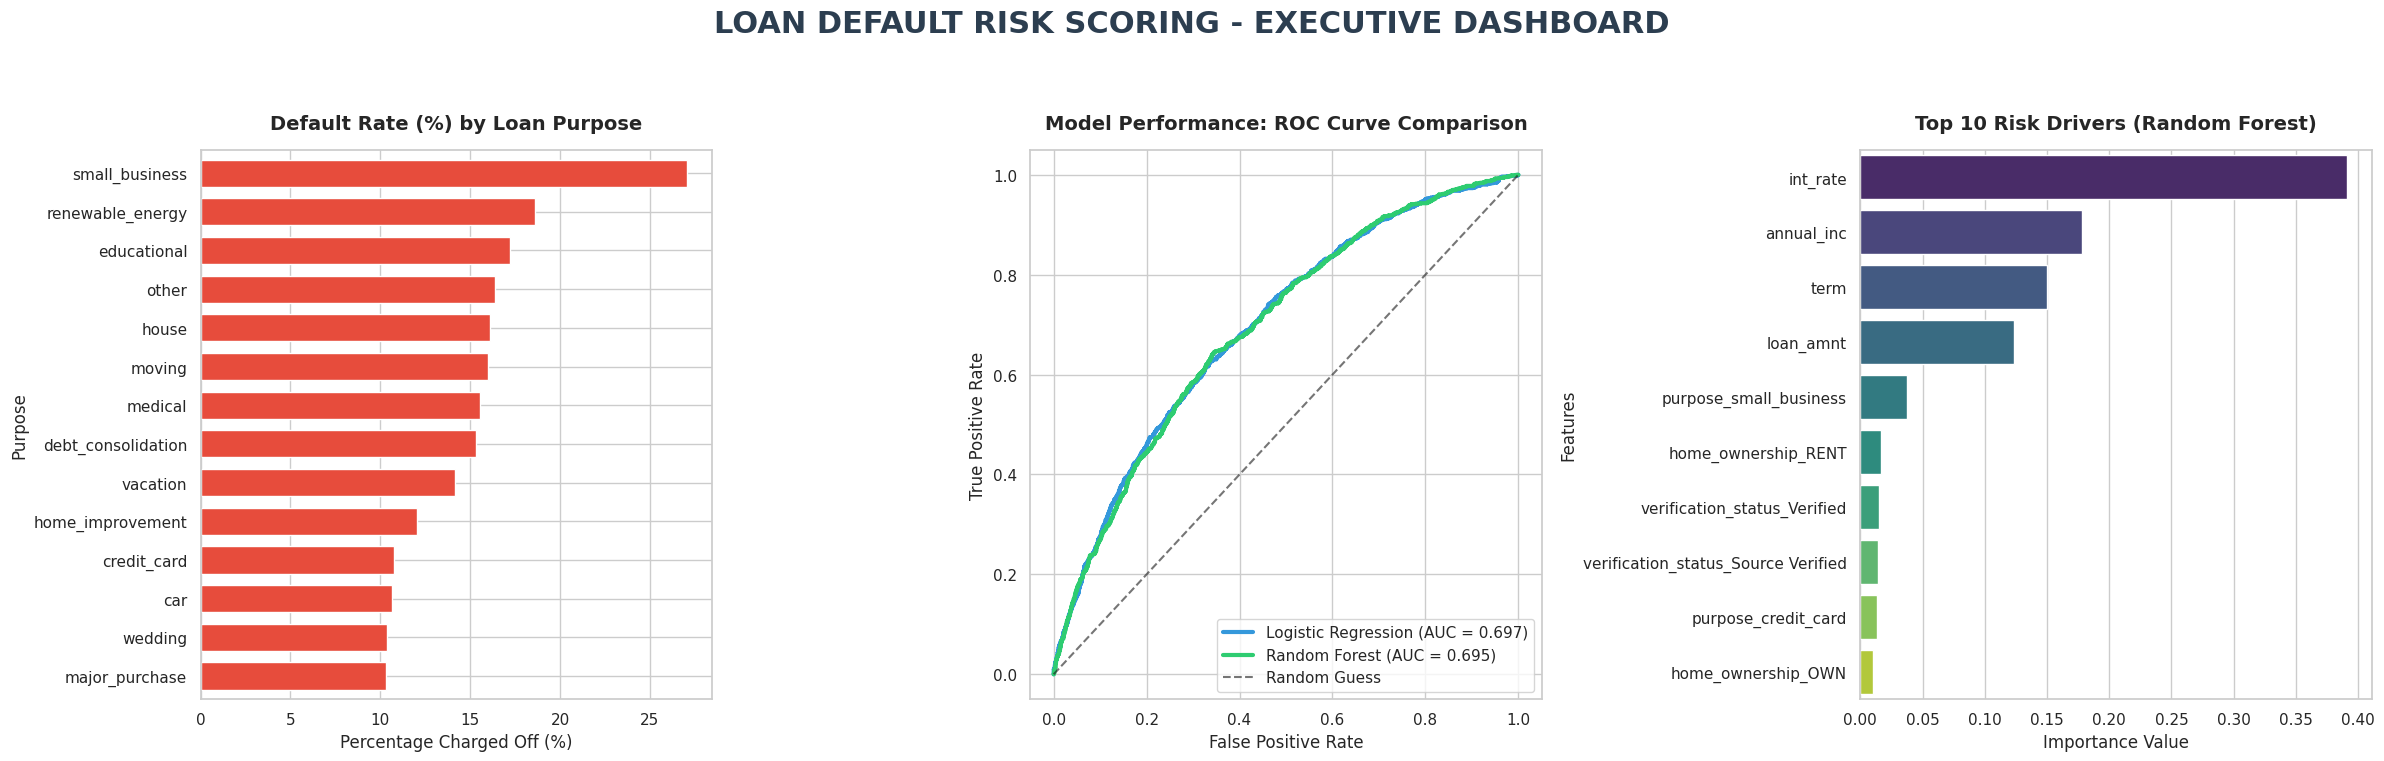

Dashboard successfully compiled and saved as horizontal PNG: loan_default_dashboard.png


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score
import numpy as np
import pandas as pd

# Set clean plotting style
sns.set_theme(style='whitegrid')

# Create a wide horizontal dashboard figure
fig = plt.figure(figsize=(24, 8))
fig.suptitle('LOAN DEFAULT RISK SCORING - EXECUTIVE DASHBOARD', fontsize=22, fontweight='bold', color='#2c3e50', y=0.98)

# --- Panel 1: Default Rate by Loan Purpose (EDA Insight) ---
ax1 = plt.subplot(1, 3, 1)
# We calculate default rates by purpose from completed_loans
purpose_counts = completed_loans.groupby(['purpose', 'loan_status']).size().unstack(fill_value=0)
purpose_pct = purpose_counts.div(purpose_counts.sum(axis=1), axis=0) * 100
purpose_pct = purpose_pct.sort_values(by='Charged Off', ascending=True) # Ascending for clean horizontal display

purpose_pct['Charged Off'].plot(kind='barh', ax=ax1, color='#e74c3c', width=0.7)
ax1.set_title('Default Rate (%) by Loan Purpose', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Percentage Charged Off (%)', fontsize=12)
ax1.set_ylabel('Purpose', fontsize=12)
ax1.tick_params(labelsize=11)

# --- Panel 2: ROC Curve Comparison (Model Performance) ---
ax2 = plt.subplot(1, 3, 2)
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_probs)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)
auc_lr = roc_auc_score(y_test, lr_probs)
auc_rf = roc_auc_score(y_test, rf_probs)

ax2.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.3f})', color='#3498db', lw=3)
ax2.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.3f})', color='#2ecc71', lw=3)
ax2.plot([0, 1], [0, 1], 'k--', label='Random Guess', alpha=0.6)

ax2.set_title('Model Performance: ROC Curve Comparison', fontsize=14, fontweight='bold', pad=15)
ax2.set_xlabel('False Positive Rate', fontsize=12)
ax2.set_ylabel('True Positive Rate', fontsize=12)
ax2.legend(loc='lower right', fontsize=11, frameon=True)
ax2.tick_params(labelsize=11)

# --- Panel 3: Feature Importances (Model Drivers) ---
ax3 = plt.subplot(1, 3, 3)
# Select top 10 features for a clean layout
top_features_df = feature_importance_df.head(10)
sns.barplot(x='Importance', y='Feature', data=top_features_df, hue='Feature', palette='viridis', legend=False, ax=ax3)
ax3.set_title('Top 10 Risk Drivers (Random Forest)', fontsize=14, fontweight='bold', pad=15)
ax3.set_xlabel('Importance Value', fontsize=12)
ax3.set_ylabel('Features', fontsize=12)
ax3.tick_params(labelsize=11)

# Adjust layout and save the dashboard as a horizontal PNG
plt.tight_layout(rect=[0, 0.03, 1, 0.93])
save_path = 'loan_default_dashboard.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Dashboard successfully compiled and saved as horizontal PNG: {save_path}")